# Image captioning with a VLM

This notebook is self-contained: it downloads the "Attention Is All You Need" PDF, parses it with docling to extract the figures, then generates a textual description for each figure using a vision-language model from Hugging Face (Qwen2-VL-2B-Instruct).

It does not depend on any local files, so it works on a fresh Colab session.

In [1]:
%pip uninstall -y -q torchvision torchaudio
%pip install -q -U --force-reinstall pillow
%pip install -q docling

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
docling-ibm-models 3.13.3 requires torchvision<1,>=0, which is not installed.
fastai 2.8.7 requires torchvision>=0.11, which is not installed.
gradio 5.50.0 requires pillow<12.0,>=8.0, but you have pillow 12.2.0 which is incompatible.


**After running the cell above, restart the kernel/runtime** (Colab: Runtime > Restart session; VS Code: the "Restart" button on the kernel) before running the rest of the notebook. Pillow's reinstall replaces a native extension module that can't be hot-swapped in an already-running process — without a restart you'll keep hitting `ImportError: cannot import name '_Ink' from 'PIL._typing'`.

In [2]:
import urllib.request
from pathlib import Path

PDF_FILENAME = "Attention Is All You Need.pdf"
urllib.request.urlretrieve("https://arxiv.org/pdf/1706.03762.pdf", PDF_FILENAME)

PDF_PATH = Path(PDF_FILENAME)
assert PDF_PATH.exists(), f"File not found: {PDF_PATH}"
PDF_PATH

PosixPath('Attention Is All You Need.pdf')

In [3]:
from docling.document_converter import DocumentConverter, PdfFormatOption
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.datamodel.base_models import InputFormat

pipeline_options = PdfPipelineOptions()
pipeline_options.do_ocr = False  # text-based PDF; avoids downloading the OCR model
pipeline_options.generate_picture_images = True  # keep rendered images so we can extract them

converter = DocumentConverter(
    format_options={
        InputFormat.PDF: PdfFormatOption(pipeline_options=pipeline_options)
    }
)
result = converter.convert(str(PDF_PATH))
doc = result.document
result.status

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

<ConversionStatus.SUCCESS: 'success'>

In [4]:
images_dir = Path("attention_is_all_you_need_parsed_docling/images")
images_dir.mkdir(parents=True, exist_ok=True)

for i, picture in enumerate(doc.pictures):
    image = picture.get_image(doc)
    if image is not None:
        image.save(images_dir / f"picture_{i}.png")

image_paths = sorted(images_dir.glob("*.png"))
assert image_paths, f"No images extracted into {images_dir}"
image_paths

[PosixPath('attention_is_all_you_need_parsed_docling/images/picture_0.png'),
 PosixPath('attention_is_all_you_need_parsed_docling/images/picture_1.png'),
 PosixPath('attention_is_all_you_need_parsed_docling/images/picture_2.png'),
 PosixPath('attention_is_all_you_need_parsed_docling/images/picture_3.png'),
 PosixPath('attention_is_all_you_need_parsed_docling/images/picture_4.png'),
 PosixPath('attention_is_all_you_need_parsed_docling/images/picture_5.png')]

In [5]:
%pip install -q -U "transformers>=4.46.0" accelerate

In [6]:
import torch
from transformers import AutoProcessor, Qwen2VLForConditionalGeneration

MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None,
)
if device == "cpu":
    model.to(device)
model.eval()
device

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

'cuda'

In [7]:
PROMPT = (
    "Describe this image in detail. It is a figure extracted from the research paper "
    "'Attention Is All You Need'. Explain what it shows, including any architecture, "
    "diagram, chart, or text visible in it."
)


def describe_image(image, prompt=PROMPT, max_new_tokens=300):
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": prompt},
            ],
        }
    ]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[image], return_tensors="pt").to(model.device)

    with torch.no_grad():
        generated_ids = model.generate(**inputs, max_new_tokens=max_new_tokens)

    output_ids = generated_ids[:, inputs["input_ids"].shape[1]:]
    return processor.batch_decode(output_ids, skip_special_tokens=True)[0].strip()

--- picture_0.png ---


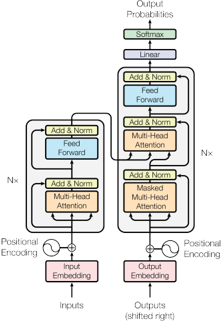

This image is a figure extracted from the research paper "Attention Is All You Need" by Vaswani et al. (2017). The figure illustrates the architecture of the Transformer model, which is a type of neural network used for sequence-to-sequence tasks such as machine translation and language modeling.

### Description:

1. **Top Left Section:**
   - **Input Embedding:** This section shows the input sequence being embedded into a fixed-length vector. The input sequence is represented as a sequence of tokens, each of which is a word or a subword unit.
   - **Positional Encoding:** This section shows how the positional information is added to the input sequence. The positional encoding is a sequence of numbers that represents the position of each token in the sequence. This information is crucial for the Transformer model to understand the relative positions of the tokens in the sequence.

2. **Top Right Section:**
   - **Output Embedding:** This section shows the output sequence being embedde

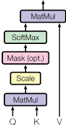

This image is a block diagram of a neural network architecture, specifically from the research paper "Attention Is All You Need." The diagram is labeled with various components and their functions, which are described below:

1. **Input Layer**: This is the topmost layer of the network, representing the input data. The input data is fed into this layer.

2. **Mask Layer**: This layer is responsible for applying a mask to the input data. The mask is a binary vector that is applied to the input data, effectively selecting or ignoring certain elements based on the mask's values.

3. **Self-Attention Layer**: This layer is the central component of the network. It performs self-attention, which is a type of attention mechanism where the network attends to its own input data. The self-attention layer is responsible for calculating the attention weights for each input element based on the input data and the mask.

4. **Multi-Head Attention Layer**: This layer is a variant of the self-attentio

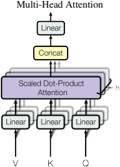

This image is a figure extracted from the research paper "Attention Is All You Need" by Vaswani et al. (2017). The figure illustrates the architecture of a multi-head attention mechanism, which is a key component of the Transformer model introduced in the paper.

### Description:

1. **Architecture Overview:**
   - The figure shows a multi-head attention mechanism, which is a type of attention mechanism used in neural networks.
   - The architecture consists of several layers, each of which performs a different type of attention operation.

2. **Layers:**
   - **Linear Layers:** There are three linear layers in the figure.
     - The first linear layer is labeled "Linear" and is followed by a "Concat" operation.
     - The second linear layer is labeled "Linear" and is followed by another "Concat" operation.
     - The third linear layer is labeled "Linear" and is followed by another "Concat" operation.
   - **Scaled Dot-Product Attention:** The attention mechanism is implemented using

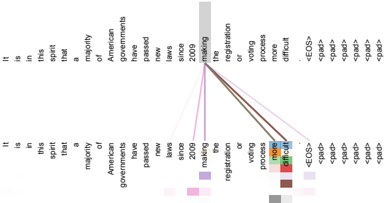

This image is a figure extracted from the research paper "Attention Is All You Need" by Vaswani et al. (2017). The figure is a visual representation of the attention mechanism used in the paper. It shows the attention weights for different words in a sentence, highlighting the relationships between words based on their importance.

### Description of the Figure:

1. **Title and Labels**:
   - The figure is titled "Attention Is All You Need" and is part of the research paper "Attention Is All You Need" by Vaswani et al. (2017).

2. **Main Elements**:
   - **Nodes**: The figure consists of nodes representing words in the sentence.
   - **Edges**: There are edges connecting the nodes, indicating the attention weights between the words.
   - **Color Coding**: The edges are colored differently to represent the attention weights:
     - **Light Purple**: High attention weights
     - **Medium Purple**: Medium attention weights
     - **Dark Purple**: Low attention weights

3. **Nodes and Edg

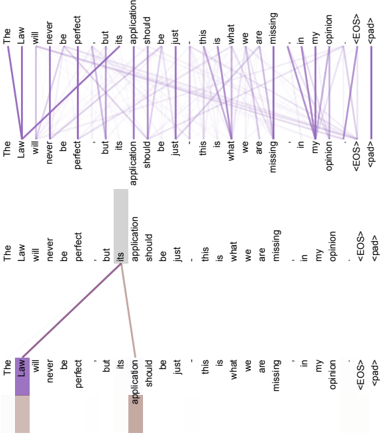

This image is a figure extracted from the research paper "Attention Is All You Need." The figure is a visual representation of the attention mechanism used in the paper. The figure shows a network of connections between different parts of the text, highlighting how attention weights are calculated and how they influence the final output.

### Description:

1. **Title and Labels**:
   - The top part of the figure has a title "Attention Is All You Need" in bold, white text.
   - The figure is divided into two main sections: the left and right sections.

2. **Left Section**:
   - The left section contains a network of connections between different parts of the text.
   - The connections are represented by lines connecting different nodes.
   - The nodes are labeled with different parts of the text, such as "The," "Law," "will," "never," "be," "perfect," "but," "its," "application," "should," "be," "should," "be," "just," "this," "is," "what," "what," "we," "are," "missing," "missing," "mi

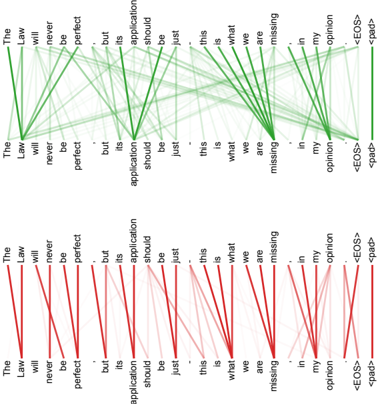

This image is a figure extracted from the research paper "Attention Is All You Need" by Vaswani et al. (2017). The figure is a visual representation of the attention mechanism used in the Transformer model, which is a type of neural network architecture for sequence modeling.

### Description of the Figure:

1. **Title and Labels**:
   - The figure is titled "Attention Is All You Need" and is part of the research paper by Vaswani et al. (2017).
   - The title is placed at the top of the figure, with the authors' names listed below it.

2. **Axes**:
   - The x-axis is labeled "The Law" and the y-axis is labeled "The Application".
   - The x-axis represents the input sequence, and the y-axis represents the output sequence.
   - The arrows connecting the points on the axes indicate the attention weights between the input and output sequences.

3. **Attention Weights**:
   - The figure shows the attention weights between the input and output sequences.
   - The attention weights are repres

In [8]:
from PIL import Image
from IPython.display import display

descriptions = {}

for path in image_paths:
    image = Image.open(path).convert("RGB")
    description = describe_image(image)
    descriptions[path.name] = description

    print(f"--- {path.name} ---")
    display(image)
    print(description)
    print()

## Save descriptions

In [9]:
import json

out_path = images_dir.parent / "image_descriptions.json"
out_path.write_text(json.dumps(descriptions, indent=2, ensure_ascii=False), encoding="utf-8")
out_path

PosixPath('attention_is_all_you_need_parsed_docling/image_descriptions.json')